# Wang et al. 2019 — Glioblastoma (GBM)
## 04 · EMT-TF expression

The expression step is **unconditional** — always the final notebook, outside the gate chain. From a
panel spanning Snail/Zeb/Twist **and** the FOXC/PRRX mesenchymal families (VIM is a marker, **not** a
TF, and is excluded), we keep factors with **detectable** expression on this dataset (frac > 0.03) and
read the earliest and latest along pseudotime, shown as **thresholded expressers over a grey manifold**
(the reference categorical overlay — not a continuous single-gene colormap, per the Sun/Chen rules).

In [1]:
import os, sys, glob, io, contextlib, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
%matplotlib inline
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.stats import spearmanr
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # 'Wang2019_Brain-3'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Brain'
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
# raw input folder = dataset minus the attempt suffix and with the Data_ prefix
raw = 'Data_' + name.split('-')[0]                      # 'Data_Wang2019_Brain'
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_feat= os.path.join(pth_data, 'features', 'biomart')
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(float(t.min()),2), '->', round(float(t.max()),2))

cells: 9634 | pseudotime range 0.0 -> 12.41


### Detection-gated EMT-TF panel; derive the early/late pair

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho, p = spearmanr(tn, x)
    rows.append((g, round(float(expr.mean()),3), round(float(x[early].mean()),3),
                 round(float(x[late].mean()),3), round(float(rho),3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\ndetectable TFs (frac>0.03): {ok.TF.tolist()}')
print(f'derived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
  ZEB1      0.699       1.363      0.854    -0.235    EARLY(root)
  ZEB2      0.670       1.085      0.746    -0.165    EARLY(root)
TWIST1      0.043       0.040      0.029    -0.076    EARLY(root)
 SNAI1      0.006       0.003      0.005     0.001 LATE(terminus)
TWIST2      0.003       0.002      0.003     0.010 LATE(terminus)
 FOXC2      0.001       0.000      0.001     0.013 LATE(terminus)
 PRRX2      0.005       0.001      0.006     0.021 LATE(terminus)
 SNAI2      0.016       0.004      0.012     0.038 LATE(terminus)
 FOXC1      0.006       0.000      0.007     0.060 LATE(terminus)
 PRRX1      0.398       0.358      0.572     0.091 LATE(terminus)

detectable TFs (frac>0.03): ['ZEB1', 'ZEB2', 'TWIST1', 'PRRX1']
derived pair: ZEB1 (early/root) <-> PRRX1 (late/terminus)


### Deliverable — `expression.pdf` (thresholded expressers on grey manifold)

overlay thresholds (upper quartile among expressers): {'ZEB1': 2.092, 'PRRX1': 1.413} | cells shown: {'ZEB1': 1683, 'PRRX1': 959}
saved expression.pdf


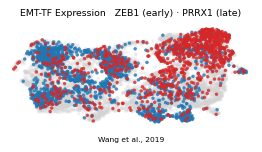

In [5]:
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5, -.14, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
print('saved expression.pdf')